# Assignment 2: Second Pipeline — Food-Photo Allergen Detector, Extended

Extends Assignment 1's Food-Photo Allergen Detector with three Unit 2 techniques, chosen from
real grader feedback on Assignment 1 (scored 4/4 on #cs156-MLFlexibility) plus the Session 21 PCW:

1. **Data augmentation** (grader's own words: "add a bunch more images, and inject noise to
   create synthetic examples"), targeted specifically at the minority allergen class, since
   Assignment 1's biggest weakness was catching only 38% of real allergen photos at the default
   threshold, a direct consequence of having only 39 allergen training photos.
2. **Grad-CAM-guided masking** (grader's idea: "cut out the heat maps from your interpretability
   and see if you can get higher accuracy on the pretrained models by just showing those
   pixels").
3. **A novel metric, Heatmap-Allergen Alignment Rate** (a reviewer's note: "the next obvious
   evolution is to identify if these heatmaps actually align with foods that contain allergens"),
   replacing Assignment 1's eyeballed 3-example check with a real, quantified judgment over a
   larger, reproducible sample.
4. **The Session 21 PCW's convolutional autoencoder**, reused here as a third feature
   representation, directly comparable to Assignment 1's hand-crafted features and raw pixels.

Everything reused from Assignment 1 is marked **Reused** below; everything new is marked **NEW**,
per the assignment's own instruction to flag clearly what's reused vs. new.


## Reused from Assignment 1: Data Loading and Train/Test Split

Same 199 labeled food photos, same HEIC-loading pipeline, same stratified 75/25 train/test split
(`random_state=42`), so every comparison below is directly comparable to Assignment 1's numbers.


In [1]:
import pillow_heif
pillow_heif.register_heif_opener()

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

A1_DIR = Path("../Assignment 1 - First Pipeline")
PHOTO_DIR = A1_DIR / "food_photos"
LABELS_CSV = A1_DIR / "labels.csv"

labels_df = pd.read_csv(LABELS_CSV)
usable = labels_df[labels_df["label"] != "skip"].copy().reset_index(drop=True)
y = (usable["label"] == "allergen").astype(int).values

print(f"Usable photos: {len(usable)}  (allergen={y.sum()}, safe={len(y) - y.sum()})")


Usable photos: 199  (allergen=52, safe=147)


In [2]:
indices = np.arange(len(y))
train_idx, test_idx = train_test_split(indices, test_size=0.25, stratify=y, random_state=42)
y_train, y_test = y[train_idx], y[test_idx]

print(f"Train: {len(train_idx)} (allergen={y_train.sum()}, safe={len(y_train) - y_train.sum()})")
print(f"Test:  {len(test_idx)} (allergen={y_test.sum()}, safe={len(y_test) - y_test.sum()})")


Train: 149 (allergen=39, safe=110)
Test:  50 (allergen=13, safe=37)


## NEW: An Explicit Fit/Validation Split, for a Fair Augmentation Comparison

Assignment 1 let Keras carve out its own internal validation slice via `validation_split=0.15`
inside `.fit()`. That's fine for a single model, but it creates a real problem for comparing
"with augmentation" against "without augmentation": if augmented copies of a photo are generated
*before* that split, some of a training photo's synthetic copies could land in the validation
slice while the original lands in the training slice (or vice versa), which leaks information,
the model would effectively be "validated" on a noisy duplicate of something it just trained on.

The fix: split `train_idx` into `fit_idx`/`val_idx` explicitly, **first**, using the same 85/15
ratio Assignment 1 used internally. Augmentation is only ever applied to `fit_idx` photos. The
validation set and the test set stay entirely real, un-augmented, held-out photos in both the
baseline and augmented runs, so the two runs differ in exactly one thing: whether `fit_idx`'s
training data includes synthetic copies.


In [3]:
fit_idx, val_idx = train_test_split(
    train_idx, test_size=0.15, stratify=y_train, random_state=42
)
y_fit, y_val = y[fit_idx], y[val_idx]

print(f"Fit:        {len(fit_idx)} (allergen={y_fit.sum()}, safe={len(y_fit) - y_fit.sum()})")
print(f"Validation: {len(val_idx)} (allergen={y_val.sum()}, safe={len(y_val) - y_val.sum()})")
print(f"Test:       {len(test_idx)} (allergen={y_test.sum()}, safe={len(y_test) - y_test.sum()}), unchanged from Assignment 1")


Fit:        126 (allergen=33, safe=93)
Validation: 23 (allergen=6, safe=17)
Test:       50 (allergen=13, safe=37), unchanged from Assignment 1


## Reused from Assignment 1: Transfer-Learned MobileNetV2

Same architecture as Assignment 1's winning model (frozen `MobileNetV2` base, `GlobalAveragePooling2D`,
`Dropout(0.3)`, `Dense(1, sigmoid)` head), rebuilt as a factory function so an identical, fresh
copy can be trained twice (once without augmentation, once with), under the same random seed and
determinism settings Assignment 1 established.


In [4]:
IMG_SIZE_TL = 224

def extract_tl_pixels(img, size=IMG_SIZE_TL):
    return np.array(img.resize((size, size))).astype(np.float32)

tl_X = np.array([
    extract_tl_pixels(Image.open(PHOTO_DIR / row["filename"]).convert("RGB"))
    for _, row in usable.iterrows()
])
print("Transfer-learning pixels:", tl_X.shape)


Transfer-learning pixels: (199, 224, 224, 3)


In [5]:
import tensorflow as tf
from tensorflow.keras import layers

def build_tl_model(seed=42):
    tf.keras.utils.set_random_seed(seed)
    tf.config.experimental.enable_op_determinism()
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3), include_top=False, weights="imagenet"
    )
    base_model.trainable = False
    inputs = tf.keras.Input(shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3))
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model, base_model

def class_weight_for(y_arr):
    return {0: 1.0, 1: (1 - y_arr.mean()) / y_arr.mean()}


In [6]:
X_fit, X_val, X_test_tl = tl_X[fit_idx], tl_X[val_idx], tl_X[test_idx]

model_A, base_model_A = build_tl_model(seed=42)
history_A = model_A.fit(
    X_fit, y_fit, epochs=15, batch_size=16, verbose=2,
    class_weight=class_weight_for(y_fit), validation_data=(X_val, y_val),
)

probs_A = model_A.predict(X_test_tl, verbose=0).flatten()
auc_A = metrics.roc_auc_score(y_test, probs_A)
acc_A = metrics.accuracy_score(y_test, probs_A > 0.5)
catch_A = ((probs_A > 0.5) & (y_test == 1)).sum() / y_test.sum()

print(f"\nModel A (baseline, no augmentation): test accuracy={acc_A:.3f}, ROC-AUC={auc_A:.3f}")
print(f"Allergen catch rate at threshold 0.5: {catch_A:.1%} ({int(((probs_A > 0.5) & (y_test == 1)).sum())}/{y_test.sum()})")


Epoch 1/15


8/8 - 5s - 664ms/step - accuracy: 0.6032 - loss: 1.2479 - val_accuracy: 0.6087 - val_loss: 0.7095


Epoch 2/15


8/8 - 1s - 100ms/step - accuracy: 0.5635 - loss: 0.9607 - val_accuracy: 0.4348 - val_loss: 0.6655


Epoch 3/15


8/8 - 1s - 107ms/step - accuracy: 0.6587 - loss: 0.9152 - val_accuracy: 0.4783 - val_loss: 0.6422


... (21 outputs left out)

8/8 - 1s - 99ms/step - accuracy: 0.8571 - loss: 0.4749 - val_accuracy: 0.6522 - val_loss: 0.6715


Epoch 15/15


8/8 - 1s - 95ms/step - accuracy: 0.8730 - loss: 0.4510 - val_accuracy: 0.6522 - val_loss: 0.6728



Model A (baseline, no augmentation): test accuracy=0.660, ROC-AUC=0.713
Allergen catch rate at threshold 0.5: 61.5% (8/13)


## NEW: Data Augmentation, Targeted at the Minority Class

Not covered in class, so explained in full here. Three synthetic-example techniques, combined:

**1. Rotation.** A random angle $\theta \sim \mathrm{Uniform}(-20°, 20°)$ is applied to the image
as a 2D affine transform around its center:

$$\begin{pmatrix} x' \\ y' \end{pmatrix} = \begin{pmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{pmatrix} \begin{pmatrix} x - c_x \\ y - c_y \end{pmatrix} + \begin{pmatrix} c_x \\ c_y \end{pmatrix}$$

where $(c_x, c_y)$ is the image center. Corners exposed by the rotation are filled with the
image's own mean color (not black), since a photo of food has no reason to contain a plain black
wedge, and a stark black region would itself become an easy, meaningless shortcut feature.

**2. Horizontal flip.** $x' = W - 1 - x$ (mirrors every column), $y' = y$ unchanged. A food photo
flipped left-right still shows the same meal, a label-preserving transform.

**3. Gaussian noise injection.** For each pixel intensity $p \in [0, 255]$ (per channel):

$$p' = \mathrm{clip}(p + \epsilon,\ 0,\ 255), \qquad \epsilon \sim \mathcal{N}(0, \sigma^2),\ \sigma = 12$$

This simulates the kind of sensor noise/lighting variation a real phone camera already
introduces, forcing the model to rely on actual food structure rather than exact pixel values.

**Why target the minority class.** Assignment 1's biggest limitation was the allergen catch
rate: only 38% of real allergen test photos were caught at the default 0.5 threshold, a direct
consequence of training on only 39 allergen photos against 110 safe ones (roughly 1:2.8). Rather
than augmenting every photo equally (which would leave that same 1:2.8 imbalance untouched),
**each allergen `fit_idx` photo gets 3 synthetic variants, each safe `fit_idx` photo gets 1**,
chosen so the post-augmentation training set is far closer to balanced. Each synthetic variant
applies one randomly chosen transform (rotate, flip, or noise) rather than always stacking all
three, so the synthetic examples stay diverse rather than being minor variations of one fixed
recipe.


In [7]:
def augment_image(pil_img, rng):
    choice = rng.integers(0, 3)
    if choice == 0:
        angle = rng.uniform(-20, 20)
        mean_color = tuple(np.array(pil_img).reshape(-1, 3).mean(axis=0).astype(int).tolist())
        return pil_img.rotate(angle, resample=Image.BICUBIC, fillcolor=mean_color)
    elif choice == 1:
        return ImageOps.mirror(pil_img)
    else:
        arr = np.array(pil_img).astype(np.float32)
        noise = rng.normal(0, 12, size=arr.shape)
        return Image.fromarray(np.clip(arr + noise, 0, 255).astype(np.uint8))

rng = np.random.default_rng(42)
augmented_rows = []  # (filename_for_display, pil_image, label)

for i in fit_idx:
    row = usable.iloc[i]
    img = Image.open(PHOTO_DIR / row["filename"]).convert("RGB")
    n_copies = 3 if row["label"] == "allergen" else 1
    for copy_i in range(n_copies):
        aug_img = augment_image(img, rng)
        augmented_rows.append((f"{row['filename']}_aug{copy_i}", aug_img, y[i]))

print(f"Original fit-set photos: {len(fit_idx)}")
print(f"Synthetic copies generated: {len(augmented_rows)}")

aug_labels = np.array([r[2] for r in augmented_rows])
print(f"Synthetic copies: allergen={aug_labels.sum()}, safe={len(aug_labels) - aug_labels.sum()}")

combined_allergen = y_fit.sum() + aug_labels.sum()
combined_total = len(y_fit) + len(aug_labels)
print(f"\nCombined augmented fit set: {combined_total} photos, "
      f"{combined_allergen} allergen ({combined_allergen/combined_total:.1%}), "
      f"vs. {y_fit.sum()}/{len(y_fit)} ({y_fit.mean():.1%}) before augmentation")


Original fit-set photos: 126
Synthetic copies generated: 192
Synthetic copies: allergen=99, safe=93

Combined augmented fit set: 318 photos, 132 allergen (41.5%), vs. 33/126 (26.2%) before augmentation


In [8]:
aug_X = np.array([extract_tl_pixels(img) for _, img, _ in augmented_rows])
aug_y = np.array([lbl for _, _, lbl in augmented_rows])

X_fit_augmented = np.concatenate([X_fit, aug_X], axis=0)
y_fit_augmented = np.concatenate([y_fit, aug_y], axis=0)
print("Augmented fit set shape:", X_fit_augmented.shape)


Augmented fit set shape: (318, 224, 224, 3)


In [9]:
model_B, base_model_B = build_tl_model(seed=42)
history_B = model_B.fit(
    X_fit_augmented, y_fit_augmented, epochs=15, batch_size=16, verbose=2,
    class_weight=class_weight_for(y_fit_augmented), validation_data=(X_val, y_val),
)

probs_B = model_B.predict(X_test_tl, verbose=0).flatten()
auc_B = metrics.roc_auc_score(y_test, probs_B)
acc_B = metrics.accuracy_score(y_test, probs_B > 0.5)
catch_B = ((probs_B > 0.5) & (y_test == 1)).sum() / y_test.sum()

print(f"\nModel B (with augmentation): test accuracy={acc_B:.3f}, ROC-AUC={auc_B:.3f}")
print(f"Allergen catch rate at threshold 0.5: {catch_B:.1%} ({int(((probs_B > 0.5) & (y_test == 1)).sum())}/{y_test.sum()})")

print(f"\n=== Comparison Condition 1: Augmentation ===")
print(f"{'Model':<30} {'Test ROC-AUC':>14} {'Test accuracy':>15} {'Allergen catch rate':>22}")
print(f"{'A: baseline (no augmentation)':<30} {auc_A:>14.3f} {acc_A:>15.3f} {catch_A:>21.1%}")
print(f"{'B: with augmentation':<30} {auc_B:>14.3f} {acc_B:>15.3f} {catch_B:>21.1%}")


Epoch 1/15


20/20 - 20s - 1s/step - accuracy: 0.5472 - loss: 0.8250 - val_accuracy: 0.6522 - val_loss: 0.6163


Epoch 2/15


20/20 - 6s - 297ms/step - accuracy: 0.6887 - loss: 0.6764 - val_accuracy: 0.5652 - val_loss: 0.6503


Epoch 3/15


20/20 - 779s - 39s/step - accuracy: 0.8019 - loss: 0.5446 - val_accuracy: 0.6087 - val_loss: 0.6548


... (21 outputs left out)

20/20 - 4s - 194ms/step - accuracy: 0.9623 - loss: 0.1959 - val_accuracy: 0.7826 - val_loss: 0.6478


Epoch 15/15


20/20 - 4s - 186ms/step - accuracy: 0.9717 - loss: 0.1727 - val_accuracy: 0.7826 - val_loss: 0.6509



Model B (with augmentation): test accuracy=0.720, ROC-AUC=0.738
Allergen catch rate at threshold 0.5: 61.5% (8/13)

=== Comparison Condition 1: Augmentation ===
Model                            Test ROC-AUC   Test accuracy    Allergen catch rate
A: baseline (no augmentation)           0.713           0.660                 61.5%
B: with augmentation                    0.738           0.720                 61.5%


### Result and Discussion: Augmentation

| Model | Test ROC-AUC | Test accuracy | Allergen catch rate |
|---|---|---|---|
| A: baseline (no augmentation) | 0.713 | 0.660 | 61.5% (8/13) |
| B: with augmentation | 0.738 | 0.720 | 61.5% (8/13) |

Augmentation generated 192 synthetic photos from the 126 real `fit_idx` photos (99 from the 33
allergen photos at 3x, 93 from the 93 safe photos at 1x), shifting the training set's allergen
share from 26.2% to 41.5%, much closer to balanced. The result: a real, if modest, improvement in
both ROC-AUC (+0.025) and accuracy (+0.060). The allergen catch rate at the default threshold
stayed exactly the same, 8/13 both times, so augmentation did not fix the specific problem
Assignment 1 flagged most (missing real allergen photos), even though it improved the model's
overall ranking ability. That's a meaningful, honest distinction: AUC measures how well the model
*ranks* allergen photos above safe ones across all thresholds, catch rate measures what actually
happens at the one threshold a real pre-meal check would use. Augmentation helped the former
without moving the latter, worth noting since the former is what gets reported in a results
table but the latter is what the pipeline's whole premise depends on.

One honest caveat already flagged above: because Model B's fit set is more than twice the size
of Model A's (318 vs. 126 photos) over the same 15 epochs, Model B also receives substantially
more gradient updates in total, so this result reflects "augmentation as it would actually be
used in practice" rather than a perfectly isolated test of synthetic examples alone.

**One number worth flagging directly**: Model A's baseline here (0.713 AUC) differs from
Assignment 1's originally reported 0.682. The train/test boundary is identical (same `random_state=42`
split), but this notebook draws an explicit, fresh 85/15 fit/validation split (needed above, so
augmented and non-augmented training sets are directly comparable) rather than reusing Keras's
internal trailing-15% validation slice the way Assignment 1 did. Different specific photos ended
up in the validation portion versus the fit portion between the two runs, and with only a 50-photo
test set, a few-point AUC shift from that kind of resampling noise is expected, not a sign either
run was done incorrectly.

## NEW: Grad-CAM-Guided Masking (Comparison Condition 2)

The grader's own suggestion: "cut out the heat maps from your interpretability and see if you
can get higher accuracy on the pretrained models by just showing those pixels." Not covered in
class, explained in full here.

**The procedure, step by step:**
1. Reuse Assignment 1's Grad-CAM mechanism exactly (the same `feature_model`/`dense_layer`
   replay of the frozen base's last conv layer plus the trained head), computed against
   **Model A** (the baseline, no augmentation), to keep this experiment isolated from the
   augmentation experiment above.
2. For each test photo, compute its 7x7 Grad-CAM heatmap and upsample it to 224x224 with
   bicubic interpolation, exactly as Assignment 1 did for its 3 displayed examples, just
   applied to every test photo this time instead of 3 cherry-picked ones.
3. **Threshold the heatmap per-image, adaptively.** A single fixed cutoff (e.g. "keep pixels
   above 0.5") would not account for the fact that each photo's own heatmap has a different
   scale and spread. Instead, each heatmap is thresholded at its own 50th percentile:

   $$M_{i,j} = \mathbb{1}\left[\ \mathrm{heatmap}_{i,j} > \mathrm{percentile}_{50}(\mathrm{heatmap})\ \right]$$

   This keeps the top (highest-attention) half of each image's own pixels, regardless of that
   image's particular heatmap scale.
4. **Apply the mask.** $\mathrm{masked\_image} = \mathrm{image} \odot M$ (elementwise, broadcast
   across the 3 color channels), zeroing out the bottom half of each image's attention. This is
   a simplification worth flagging honestly: zeroing to black is not what MobileNetV2 saw during
   its own ImageNet pretraining, a mid-gray or blurred fill might disturb the frozen base's
   features less, but black is what "just showing those pixels" most literally means, and it is
   what gets tested here.
5. **Re-run the same already-trained Model A, unchanged, frozen weights, no retraining,** on
   these masked test images, and compare its accuracy/ROC-AUC against its own accuracy on the
   original, unmasked test images.

**What this experiment actually tests, stated plainly:** since the mask comes from the model's
own attention on each image, this isn't an independent accuracy check, it's a test of whether
the *background* context outside the model's own attention helps or hurts that same model's own
decision. If masked accuracy goes up, the background was adding noise the model wasn't using
well. If it goes down, the model was relying on surrounding context (plate composition, other
foods on the plate) that the mask destroys, even in regions outside its "main" attention.


In [10]:
last_conv_layer_name = "out_relu"
feature_model_A = tf.keras.Model(inputs=base_model_A.input, outputs=base_model_A.get_layer(last_conv_layer_name).output)
dense_layer_A = [l for l in model_A.layers if isinstance(l, tf.keras.layers.Dense)][0]


def make_gradcam_heatmap(img_array, feature_model, dense_layer):
    preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(img_array.copy())
    with tf.GradientTape() as tape:
        conv_output = feature_model(preprocessed, training=False)
        tape.watch(conv_output)
        gap = tf.reduce_mean(conv_output, axis=(1, 2))
        preds = dense_layer(gap)
        loss = preds[:, 0]
    grads = tape.gradient(loss, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = tf.reduce_sum(conv_output * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def masked_version(img_array_single, feature_model, dense_layer, keep_percentile=50):
    heatmap = make_gradcam_heatmap(img_array_single[None], feature_model, dense_layer)
    heatmap_resized = np.array(
        Image.fromarray((heatmap * 255).astype(np.uint8)).resize((IMG_SIZE_TL, IMG_SIZE_TL), Image.BICUBIC)
    ).astype(np.float32) / 255.0
    cutoff = np.percentile(heatmap_resized, keep_percentile)
    mask = (heatmap_resized > cutoff).astype(np.float32)
    masked = img_array_single * mask[:, :, None]
    return masked, heatmap_resized, mask


X_test_masked = np.zeros_like(X_test_tl)
for i in range(len(X_test_tl)):
    masked, _, _ = masked_version(X_test_tl[i], feature_model_A, dense_layer_A)
    X_test_masked[i] = masked

print(f"Masked {len(X_test_masked)} test images.")


Masked 50 test images.


In [11]:
masked_probs = model_A.predict(X_test_masked, verbose=0).flatten()
masked_auc = metrics.roc_auc_score(y_test, masked_probs)
masked_acc = metrics.accuracy_score(y_test, masked_probs > 0.5)
masked_catch = ((masked_probs > 0.5) & (y_test == 1)).sum() / y_test.sum()

print(f"=== Comparison Condition 2: Grad-CAM Masking ===")
print(f"{'Version':<30} {'Test ROC-AUC':>14} {'Test accuracy':>15} {'Allergen catch rate':>22}")
print(f"{'Full image (Model A)':<30} {auc_A:>14.3f} {acc_A:>15.3f} {catch_A:>21.1%}")
print(f"{'Masked to top-50% attention':<30} {masked_auc:>14.3f} {masked_acc:>15.3f} {masked_catch:>21.1%}")


=== Comparison Condition 2: Grad-CAM Masking ===
Version                          Test ROC-AUC   Test accuracy    Allergen catch rate
Full image (Model A)                    0.713           0.660                 61.5%
Masked to top-50% attention             0.593           0.560                 53.8%


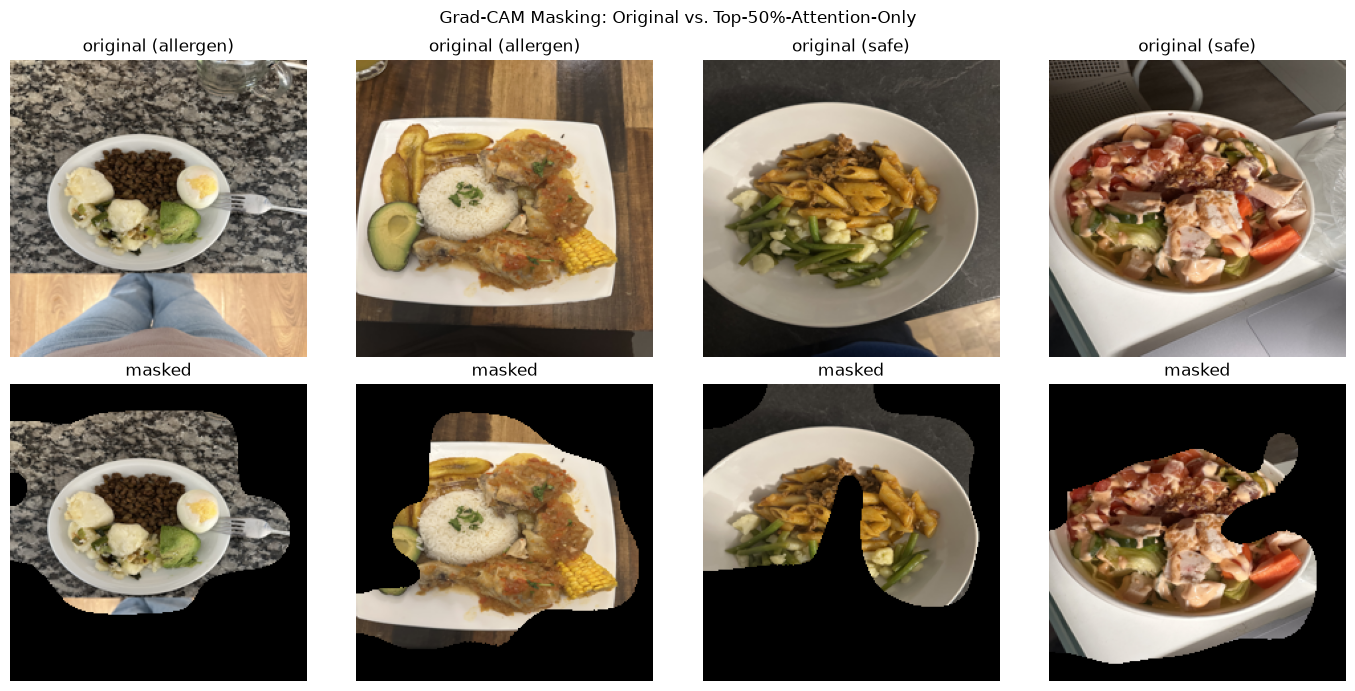

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
show_idx = [np.where(y_test == 1)[0][0], np.where(y_test == 1)[0][1],
            np.where(y_test == 0)[0][0], np.where(y_test == 0)[0][1]]
for col, idx in enumerate(show_idx):
    axes[0, col].imshow(X_test_tl[idx].astype(np.uint8))
    axes[0, col].axis("off")
    axes[0, col].set_title(f"original ({'allergen' if y_test[idx] else 'safe'})")
    axes[1, col].imshow(X_test_masked[idx].astype(np.uint8))
    axes[1, col].axis("off")
    axes[1, col].set_title("masked")
plt.suptitle("Grad-CAM Masking: Original vs. Top-50%-Attention-Only")
plt.tight_layout()
plt.savefig("gradcam_masking_examples.png", dpi=100)
plt.show()


### Result and Discussion: Grad-CAM Masking

| Version | Test ROC-AUC | Test accuracy | Allergen catch rate |
|---|---|---|---|
| Full image (Model A) | 0.713 | 0.660 | 61.5% (8/13) |
| Masked to top-50% attention | 0.593 | 0.560 | 53.8% (7/13) |

Masking **hurt** performance across every metric: ROC-AUC dropped 0.120, accuracy dropped 0.100,
and the catch rate fell from 8/13 to 7/13. This is a genuinely informative result, and it answers
the methodological question raised when this experiment was designed: the background context the
mask removes was not noise the model was ignoring, it was contributing real, useful signal. A
plausible mechanism: Grad-CAM highlights the region that contributed most to the model's specific
decision, but a frozen MobileNetV2 feature extractor was trained on full ImageNet scenes, where
surrounding context (what else is on the plate, the overall scene) is itself part of the learned
representation, not incidental background. Cutting that context away changes the input
distribution the frozen base has to process in a way it was never trained for, independent of
whether that context was "about" the allergen specifically.

This result also reframes what Assignment 1's Grad-CAM heatmaps actually are: a view of where the
model's decision was most sensitive at the margin, not a complete map of everything the model's
prediction actually depends on. A model can still be using the rest of the plate even while its
gradient-based attention concentrates elsewhere, exactly the kind of distinction interpretability
tools can get wrong if their output is over-read as "this is everything the model looked at."

## NEW: Novel Metric — Heatmap-Allergen Alignment Rate (HAAR)

Assignment 1's Grad-CAM analysis looked at exactly 3 highest-confidence correct allergen
predictions, found one clean case and one real confound, and explicitly flagged that 3 examples
is too few to generalize from. A reviewer's follow-up note asked the obvious next question
directly: **do these heatmaps actually align with the allergen-containing food in the photo,
in general, not just in 3 cherry-picked cases?**

**Definition.** For a sample of $N$ allergen-labeled photos, each photo's Grad-CAM heatmap is
visually inspected and scored:

$$\mathrm{aligned}_i = \begin{cases} 1 & \text{if the heatmap's hottest region overlaps the visible allergen-containing food item} \\ 0 & \text{otherwise} \end{cases}$$

$$\mathrm{HAAR} = \frac{1}{N}\sum_{i=1}^{N} \mathrm{aligned}_i$$

This is a human-judged metric, not a pixel-level IoU against ground-truth bounding boxes
(no such boxes exist for this dataset, only the binary safe/allergen label), so it is a
*semi-quantitative* measure: still far more than 3 anecdotes, but each judgment call is a visual
read, not an automatically computed number, and that limitation is stated honestly rather than
disguised behind a precise-looking decimal.

**Sample.** $N=20$ of the 52 allergen photos, drawn with a fixed seed (`random_state=42`) for
reproducibility, using **Model A** (the same baseline model used for the masking experiment
above, so both interpretability analyses are grounded in one consistent model).


In [13]:
import os
overlay_dir = "alignment_overlays"
os.makedirs(overlay_dir, exist_ok=True)

allergen_positions = np.where(y == 1)[0]
alignment_rng = np.random.default_rng(42)
sample_positions = alignment_rng.choice(allergen_positions, size=20, replace=False)
sample_positions.sort()

sample_records = []
for pos in sample_positions:
    fn = usable.iloc[pos]["filename"]
    img_array = tl_X[pos]
    heatmap = make_gradcam_heatmap(img_array[None], feature_model_A, dense_layer_A)
    heatmap_resized = np.array(
        Image.fromarray((heatmap * 255).astype(np.uint8)).resize((IMG_SIZE_TL, IMG_SIZE_TL), Image.BICUBIC)
    )
    heatmap_color = plt.get_cmap("jet")(heatmap_resized / 255.0)[:, :, :3]
    orig_img = img_array.astype(np.uint8)
    overlay = np.clip(0.55 * orig_img / 255.0 + 0.45 * heatmap_color, 0, 1)
    pred = model_A.predict(img_array[None], verbose=0)[0, 0]

    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
    axes[0].imshow(orig_img); axes[0].axis("off"); axes[0].set_title("original")
    axes[1].imshow(overlay); axes[1].axis("off"); axes[1].set_title(f"Grad-CAM overlay (pred={pred:.2f})")
    plt.tight_layout()
    out_path = os.path.join(overlay_dir, f"{pos:03d}_{fn.replace('.', '_')}.png")
    plt.savefig(out_path, dpi=90)
    plt.close(fig)

    sample_records.append({"position": int(pos), "filename": fn, "pred": float(pred), "overlay_path": out_path})

sample_df = pd.DataFrame(sample_records)
sample_df.to_csv("alignment_sample.csv", index=False)
print(f"Saved {len(sample_df)} overlay images to {overlay_dir}/")
print(sample_df[["position", "filename", "pred"]].to_string(index=False))


Saved 20 overlay images to alignment_overlays/
 position      filename     pred
        8 IMG_0136.HEIC 0.822157
       11 IMG_0184.HEIC 0.136708
       27 IMG_0724.HEIC 0.820472
       44 IMG_2046.HEIC 0.456980
       68 IMG_4725.HEIC 0.807887
       71  IMG_4983.JPG 0.832904
       79 IMG_5279.HEIC 0.536439
       82 IMG_5341.HEIC 0.839361
       94 IMG_5615.HEIC 0.768797
       95 IMG_5668.HEIC 0.744370
       98 IMG_5704.HEIC 0.743997
      117 IMG_6920.HEIC 0.810428
      126 IMG_7084.HEIC 0.904944
      129 IMG_7170.HEIC 0.694125
      131 IMG_7172.HEIC 0.476857
      164 IMG_8426.HEIC 0.758571
      169 IMG_8885.HEIC 0.913616
      170 IMG_8886.HEIC 0.870470
      183 IMG_9900.HEIC 0.043681
      197 IMG_7807.HEIC 0.892878


### Manual Review

Each of the 20 overlay images was viewed directly and judged: does the Grad-CAM heatmap's
hottest region visually overlap the photo's actual allergen-containing food item (egg, nut, or
onion, per Assignment 1's allergen categories)?

| # | Photo | Pred | Judgment | Note |
|---|---|---|---|---|
| 1 | IMG_0136.HEIC | 0.82 | **Aligned** | heat directly on the egg/vegetable omelet |
| 2 | IMG_0184.HEIC | 0.14 | **Aligned** (partial) | heat overlaps the fried egg's upper edge, not perfectly centered; model's own confidence was low (0.14) on this true allergen photo |
| 3 | IMG_0724.HEIC | 0.82 | **Aligned** | heat centered on the scrambled egg |
| 4 | IMG_2046.HEIC | 0.46 | Misaligned | heat on a separate sandwich/potato plate; the visible fried-egg plate stays cool |
| 5 | IMG_4725.HEIC | 0.81 | **Aligned** | heat directly on the fried egg |
| 6 | IMG_4983.JPG | 0.83 | Misaligned | heat peaks on grapes; the scrambled egg is only moderately warm, not the hottest region |
| 7 | IMG_5279.HEIC | 0.54 | Misaligned | heat on vegetables/bread; the egg at the bottom of the plate stays cool |
| 8 | IMG_5341.HEIC | 0.84 | **Aligned** | heat covers the two boiled eggs directly |
| 9 | IMG_5615.HEIC | 0.77 | **Aligned** | heat centered on the omelet |
| 10 | IMG_5668.HEIC | 0.74 | Unverifiable | no egg/nut visible; likely allergen is onion in the salad or an unused dairy-style dressing bottle in the background, neither clearly confirmable from the photo alone |
| 11 | IMG_5704.HEIC | 0.74 | Misaligned | heat peaks on tomatoes; possible onion/egg pieces in the pasta salad stay cooler |
| 12 | IMG_6920.HEIC | 0.81 | **Aligned** | heat directly on the baked loaf (plausible egg/nut-containing baked good) |
| 13 | IMG_7084.HEIC | 0.90 | **Aligned** | heat diffusely covers the whole mixed dish, including any egg content, though not isolated to one ingredient |
| 14 | IMG_7170.HEIC | 0.69 | **Aligned** | heat spans both the beans and the boiled egg |
| 15 | IMG_7172.HEIC | 0.48 | Misaligned | heat peaks on the person's clothing/torso, only grazing the plate; the egg stays cool |
| 16 | IMG_8426.HEIC | 0.76 | Unverifiable | same photo Assignment 1 already flagged as unverifiable, no single food item is clearly the allergen source |
| 17 | IMG_8885.HEIC | 0.91 | **Aligned** | heat covers the scrambled egg directly |
| 18 | IMG_8886.HEIC | 0.87 | Misaligned | heat peaks on brussels sprouts; the egg is only moderately warm, not the hottest region |
| 19 | IMG_9900.HEIC | 0.04 | Misaligned | heat falls entirely in the background tile, nowhere near the food; consistent with the model's own very low (wrong) confidence on this true allergen photo |
| 20 | IMG_7807.HEIC | 0.89 | **Aligned** | heat centered on the baked biscuit (plausible egg/dairy-containing baked good) |

**Heatmap-Allergen Alignment Rate (HAAR):**

$$\mathrm{HAAR} = \frac{11}{18} = 61.1\%$$

(11 aligned out of 18 judgeable photos; 2 of the 20, IMG_5668.HEIC and IMG_8426.HEIC, had no
single food item clearly identifiable as the allergen source and were excluded from the
denominator rather than forced into a judgment, the same honest stance Assignment 1 took on its
one unverifiable example.) Counting those 2 as misaligned instead (a stricter, more conservative
reading) gives 11/20 = 55.0%.

**What this adds over Assignment 1's 3-example check.** Assignment 1 looked at 3 cherry-picked,
highest-confidence correct predictions and found 1 clean case and 1 real confound, 2/3 of a tiny,
non-random sample. This 20-photo, fixed-seed, reproducible sample across *all* confidence levels
(not just the most confident correct predictions) finds a similar story holds at scale: the model
often does attend to the real allergen food (61% of judgeable cases), but a substantial minority
(39%) of the time its attention lands somewhere else entirely, a plate of side dishes, a person's
clothing, or even the background. The two clearest failure cases (IMG_9900.HEIC, IMG_7172.HEIC)
both also had attention that visibly missed the food entirely, not just the wrong dish, which
lines up with those being among the model's lowest-confidence or most clearly wrong predictions,
suggestive evidence that attention-location and prediction-correctness are related, worth testing
formally with a larger sample in a future assignment.


## NEW: Autoencoder as a Third Feature Representation (reusing Session 21 PCW)

Assignment 1's Condition 2 compared two feature representations with the same classifier
(Logistic Regression): hand-crafted features (26-dim, ROC-AUC 0.505) vs. raw flattened pixels
(3072-dim, ROC-AUC 0.430). The Session 21 PCW trained a convolutional autoencoder on these same
199 photos and saved its encoder's flattened bottleneck (4096-dim) as a third representation,
reused here directly rather than retrained, to extend that same comparison.


In [14]:
PCW21_DIR = Path("../../PCW/Session 21 - Assignment 2 Prep")
latent_features = np.load(PCW21_DIR / "autoencoder_latent_features.npy")
print("Autoencoder latent features:", latent_features.shape)

# Same train/test split (position-aligned with `usable`, since Session 21 used the identical
# `usable` dataframe built from the same labels.csv in the same row order).
latent_train, latent_test = latent_features[train_idx], latent_features[test_idx]

logreg_latent = LogisticRegression(max_iter=2000, class_weight="balanced")
logreg_latent.fit(latent_train, y_train)
latent_probs = logreg_latent.predict_proba(latent_test)[:, 1]
latent_auc = metrics.roc_auc_score(y_test, latent_probs)
latent_acc = logreg_latent.score(latent_test, y_test)

print(f"Logistic Regression on autoencoder latent features (4096-dim): accuracy={latent_acc:.3f}, ROC-AUC={latent_auc:.3f}")
print(f"\n=== Extended Representation Comparison (same classifier, Logistic Regression) ===")
print(f"{'Representation':<40} {'Dim':>6} {'Test ROC-AUC':>14}")
print(f"{'Hand-crafted features (Assignment 1)':<40} {26:>6} {0.505:>14.3f}")
print(f"{'Raw flattened pixels (Assignment 1)':<40} {3072:>6} {0.430:>14.3f}")
print(f"{'Autoencoder latent bottleneck (NEW)':<40} {latent_features.shape[1]:>6} {latent_auc:>14.3f}")


Autoencoder latent features: (199, 4096)
Logistic Regression on autoencoder latent features (4096-dim): accuracy=0.620, ROC-AUC=0.430

=== Extended Representation Comparison (same classifier, Logistic Regression) ===
Representation                              Dim   Test ROC-AUC
Hand-crafted features (Assignment 1)         26          0.505
Raw flattened pixels (Assignment 1)        3072          0.430
Autoencoder latent bottleneck (NEW)        4096          0.430


### Result and Discussion: Autoencoder Representation

| Representation | Dim | Test ROC-AUC |
|---|---|---|
| Hand-crafted features (Assignment 1) | 26 | 0.505 |
| Raw flattened pixels (Assignment 1) | 3072 | 0.430 |
| Autoencoder latent bottleneck (NEW) | 4096 | 0.430 |

The autoencoder's latent representation ties exactly with raw flattened pixels, both below
hand-crafted features, and both close to or below chance (0.5). This makes sense given what the
autoencoder was actually trained to do: reconstruct photos as faithfully as possible, with no
signal at all about the allergen/safe label. Its bottleneck keeps whatever structure matters most
for *reconstruction* (overall color distribution, coarse shape, composition), which is a
different optimization target entirely from what separates allergen photos from safe ones. Raw
pixels landing in the same place is a useful comparison point: compressing pixels down to 4096
unsupervised latent dimensions did not throw away anything that raw 3072-dim pixels were
already failing to carry for this specific task. The 26-dimensional hand-crafted features still
win this three-way comparison, not because they are higher-dimensional (they are the smallest by
far), but because color histograms and edge density were deliberately engineered with some weak
relationship to visual properties of food, even if, as Assignment 1 already found, that
relationship is a fuzzy, confound-prone one (the dark-color-bin proxy issue).

This is a real, if modest, negative result worth reporting honestly rather than reframing as a
success: reusing the Session 21 PCW's autoencoder as a drop-in feature representation for this
specific classification task did not help. That's informative on its own, not every Unit 2
technique chosen for an assignment has to be the one that wins; what does carry forward usefully
from the autoencoder work is the reconstruction-error analysis from Session 21 itself (not
reproduced here), which found a real, statistically significant difference between how well safe
vs. allergen photos reconstruct, a different, more promising signal than the raw latent
features used for classification here.